# Comparing skill extraction methods

Each panel compares the baseline ESCO label matcher (grey) with the LLM (blue) on one score from 0 to 1; the `ALL` row summarizes all programmes, and the remaining rows show each programme separately. Overall precision is similar (0.872 for the baseline and 0.862 for the LLM), while the LLM has higher recall (0.957 vs. 0.245) and F1 (0.907 vs. 0.382). Recall is pooled and may be an upper bound because skills missed by both methods are only counted when added by hand.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "data/eval").exists():
    ROOT = ROOT.parent

scores = pd.read_csv(ROOT / "data/eval/skills_scores.csv")
programmes = ["ALL"] + sorted(scores.loc[scores["programme"] != "ALL", "programme"].unique())
metrics = ["precision", "recall", "f1"]
labels = ["All programmes" if programme == "ALL" else programme for programme in programmes]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

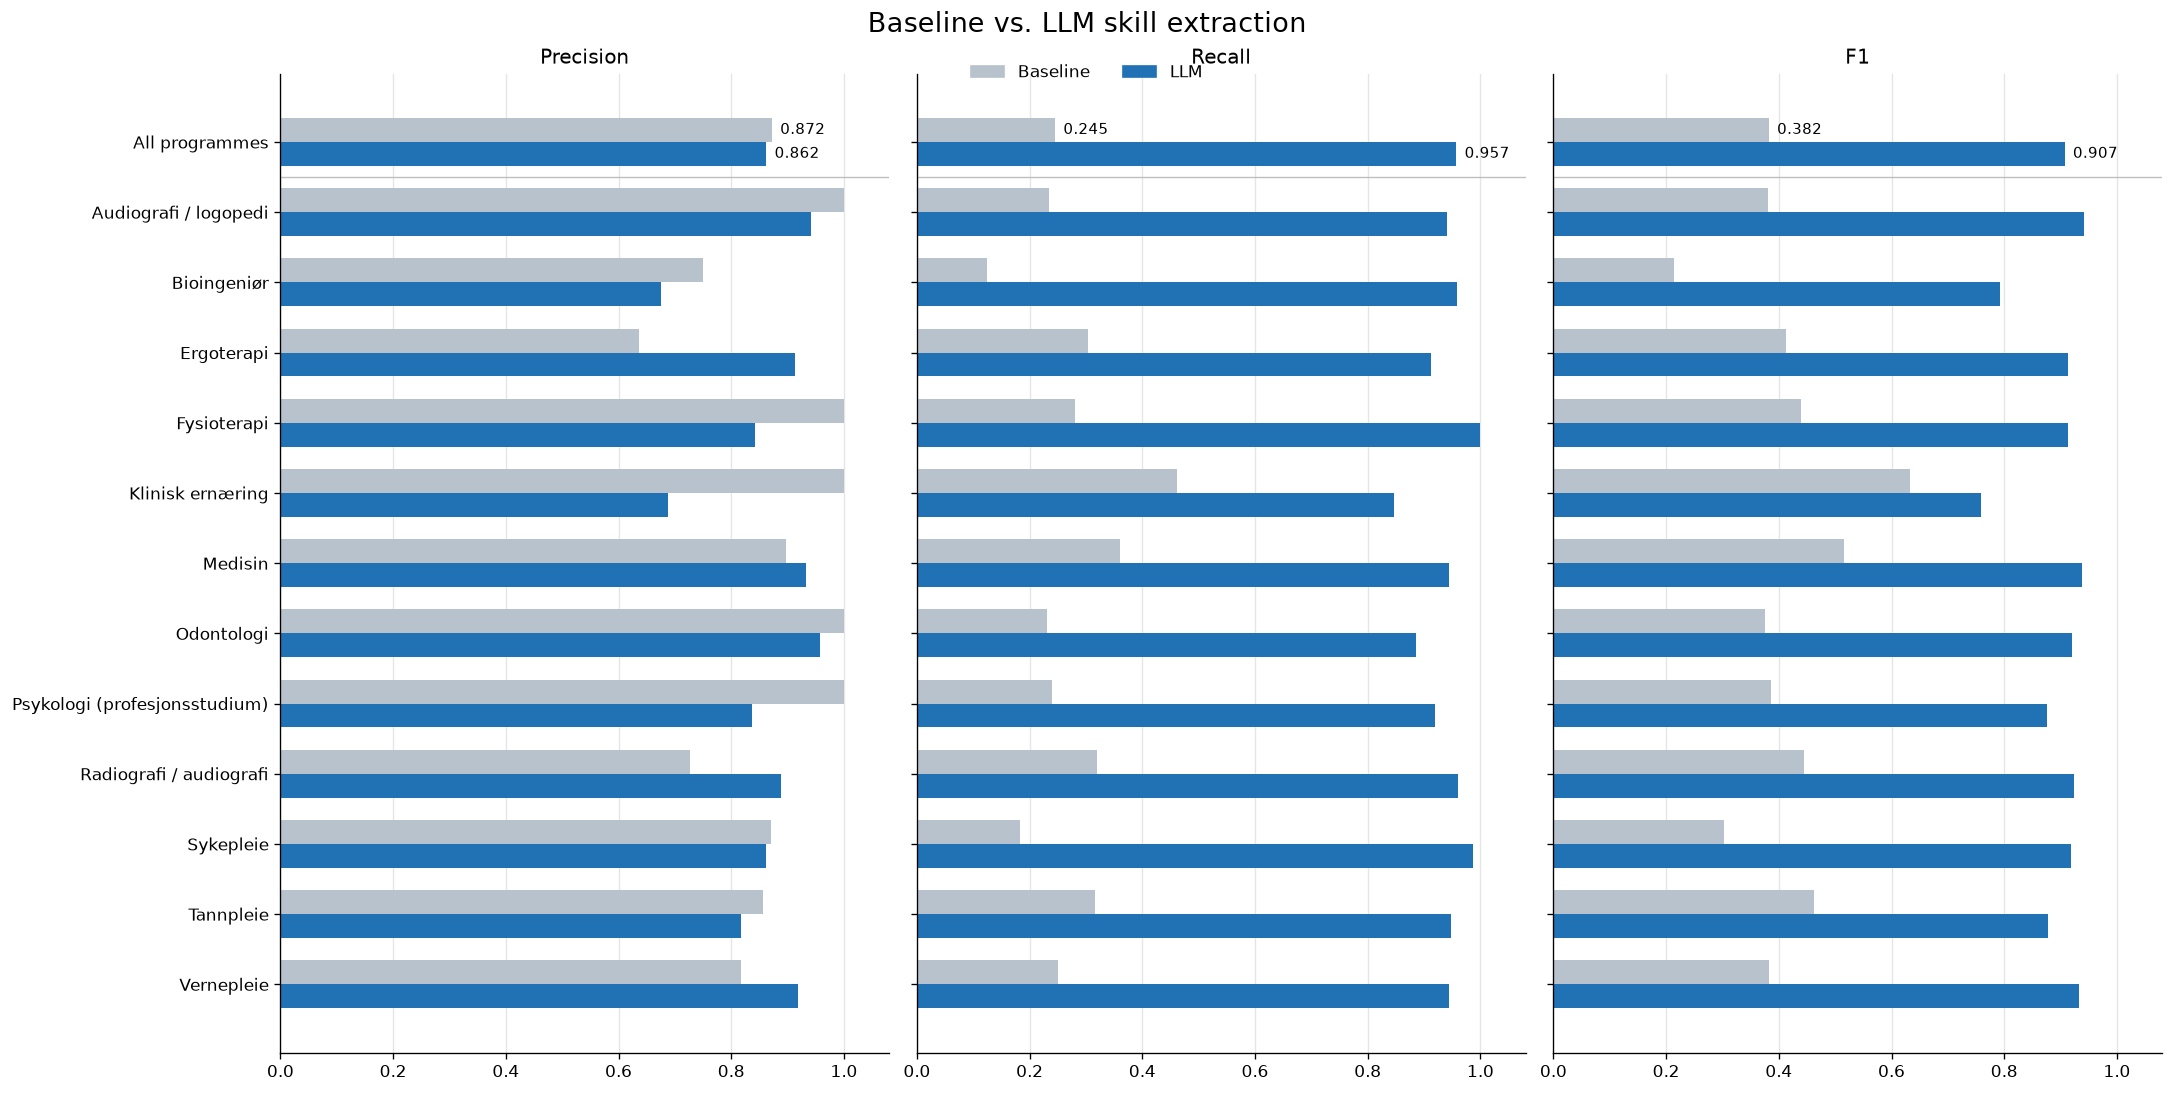

In [2]:
y = np.arange(len(programmes))
bar_height = 0.34
method_colors = {"baseline": "#B8C2CC", "llm": "#2171B5"}

fig, axes = plt.subplots(ncols=3, figsize=(18, 9), sharey=True, constrained_layout=True)
for ax, metric in zip(axes, metrics):
    values = scores.pivot(index="programme", columns="method", values=metric).loc[programmes]
    ax.barh(y - bar_height / 2, values["baseline"], height=bar_height, color=method_colors["baseline"])
    ax.barh(y + bar_height / 2, values["llm"], height=bar_height, color=method_colors["llm"])
    ax.set_title(metric.upper() if metric == "f1" else metric.capitalize())
    ax.set_xlim(0, 1.08)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.axhline(0.5, color="#bdbdbd", linewidth=0.8)

    for method, offset in (("baseline", -bar_height / 2), ("llm", bar_height / 2)):
        value = values.loc["ALL", method]
        ax.text(value + 0.015, offset, f"{value:.3f}", va="center", fontsize=9)

axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
axes[0].set_ylabel("")
fig.suptitle("Baseline vs. LLM skill extraction", fontsize=16)
fig.legend(
    handles=[
        Patch(color=method_colors["baseline"], label="Baseline"),
        Patch(color=method_colors["llm"], label="LLM"),
    ],
    loc="outside lower center",
    ncol=2,
    frameon=False,
)
fig.savefig(FIGURES / "skill_extraction_baseline_vs_llm.png", bbox_inches="tight", dpi=200)
plt.show()